# Fairness Over Time — Phase 2: Monitor (Texas, 2015–2017)

**RQ1: Does fairness hold over time?**

The four models frozen in Phase 1 (logistic regression and XGBoost, each unmitigated and mitigated) are run, **unchanged**, on Texas data from 2015, 2016 and 2017. Nothing is retrained and the 2014 preprocessing is never refit, so any change in performance or fairness comes from the data, not the models.

This notebook:
1. Loads 2014–2017 and describes how the population and the label changed
2. Checks that the data is coded the same way in every year
3. Evaluates the frozen models on each year
4. Adds bootstrap confidence intervals
5. Plots the headline chart and answers RQ1

In [1]:
%load_ext autoreload
%autoreload 2

import time
import warnings
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, roc_auc_score

from src.data import DATA_DIR, ARTIFACTS_DIR, load_acs, make_race_eth, split_data, save_split, load_split
from src.preprocess import NUMERIC_COLS, ORDINAL_COLS, NOMINAL_COLS, build_preprocessor
from src.models import make_lr, make_xgb, make_pipeline_for, fit_mitigated, load_models, MODEL_INFO
from src.fairness import (make_sensitive, group_metrics, fairness_summary, fairness_long,
                          bootstrap_gaps, evaluate_all, bootstrap_all, save_results)

warnings.filterwarnings("ignore", module="fairlearn")

## 1. Load 2014–2017 and describe the change

Each year is loaded with the same `load_acs()` function as in Phase 1. Later years are evaluated on **all of their rows** (about 129K–134K people each). 2014 is loaded here only to describe how the data changed; its official metrics stay the ones from the Phase 1 test set.

In [2]:
YEARS = [2014, 2015, 2016, 2017]
STATE = "TX"

data = {}
for year in YEARS:
    X, y, meta = load_acs(year, STATE)
    assert X.isna().sum().sum() == 0
    data[year] = (X, y, meta)
    print(f"{year}: {len(X):,} rows")

2014: 127,039 rows
2015: 128,969 rows
2016: 131,089 rows
2017: 133,880 rows


In [3]:
def summarize_year(year, X, y, meta):
    y = y.squeeze("columns").astype(int)
    row = {
        "year": year,
        "n_rows": len(X),
        "pos_rate": y.mean(),
        "median_income": meta["income"].median(),
    }
    sex_rates = y.groupby(meta["SEX"].map({1: "Male", 2: "Female"})).mean()
    for group, rate in sex_rates.items():
        row[f"pos_{group}"] = rate
    for group, rate in y.groupby(meta["race_eth"]).mean().items():
        row[f"pos_{group}"] = rate
    return row

summary = pd.DataFrame([summarize_year(yr, *data[yr]) for yr in YEARS]).set_index("year")
display(summary.round(3))

,n_rows,pos_rate,median_income,pos_Female,pos_Male,pos_Hispanic,pos_NH Asian,pos_NH Black,pos_NH Other,pos_NH White
year,,,,,,,,,,
2014,127039,0.316,34000.0,0.228,0.393,0.169,0.429,0.219,0.279,0.411
2015,128969,0.332,35000.0,0.243,0.409,0.183,0.433,0.233,0.310,0.430
2016,131089,0.342,35000.0,0.259,0.413,0.189,0.447,0.248,0.326,0.442
2017,133880,0.354,36500.0,0.272,0.425,0.200,0.473,0.267,0.317,0.453


In [4]:
# Change since 2014, in percentage points (income in dollars)
change = summary.drop(columns="n_rows") - summary.drop(columns="n_rows").loc[2014]
display((change.drop(columns="median_income") * 100).round(1))

,pos_rate,pos_Female,pos_Male,pos_Hispanic,pos_NH Asian,pos_NH Black,pos_NH Other,pos_NH White
year,,,,,,,,
2014,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2015,1.5,1.5,1.6,1.4,0.4,1.4,3.1,1.9
2016,2.5,3.1,2.0,2.0,1.8,2.9,4.6,3.1
2017,3.8,4.4,3.2,3.1,4.5,4.8,3.8,4.2


### Finding: more people earn over $50K every year (label drift)

| Year | Rows | > $50K | Median income | Women | Men | Hispanic | NH White |
|---|---|---|---|---|---|---|---|
| 2014 | 127,039 | 31.6% | $34,000 | 22.8% | 39.3% | 16.9% | 41.1% |
| 2017 | 133,880 | 35.4% | $36,500 | 27.2% | 42.5% | 20.0% | 45.3% |

- The share earning over $50K rises **3.8 points** in three years. Median income rises 7.4%, while prices rose about 3.5%, so the change is not only inflation (Phase 3 splits the two).
- **Groups move at different speeds:** the male − female gap in true rates narrows (16.5 → 15.3 points), while the NH White − Hispanic gap widens slightly (24.2 → 25.3).
- NH Other (about 2,200 people) goes up and down by several points from year to year; that is noise, so no trend should be read into it.

**Why this matters:** the label is a fixed $50,000 cutoff, so as incomes rise, more people cross it. The models were trained when fewer people did. These changes in true group rates happen **before any model is involved**, which is also why demographic parity can move even if a model does not change.

## 2. Check that the codes mean the same thing every year

A model trained in 2014 assumes each code means the same thing later. Two codes could break this:
- **Hispanic origin (`HISP`):** `race_eth` treats code 1 as "not Hispanic"; if that coding changed, the race/ethnicity groups would shift suddenly.
- **Occupation (`OCCP`):** occupation codes changed in 2018 (the reason 2018 is excluded); this checks that 2014–2017 really use the same codes.

In [5]:
#check whether Hispanic == 1 mean "not Hispanic" in other years
shares = pd.DataFrame({yr: data[yr][2]["race_eth"].value_counts(normalize=True)
                       for yr in [2014, 2015, 2016, 2017]}).T
display(shares.round(3))

race_eth,NH White,Hispanic,NH Black,NH Asian,NH Other
2014,0.535,0.309,0.095,0.043,0.018
2015,0.529,0.315,0.093,0.046,0.018
2016,0.524,0.317,0.094,0.048,0.018
2017,0.521,0.317,0.091,0.050,0.020


**Race/ethnicity shares change smoothly** (Hispanic 30.9% → 31.7%, NH Asian 4.3% → 5.0%, NH White 53.5% → 52.1%), with no sudden jump, so the `HISP` coding is the same in every year.

In [6]:
models =load_models()
pre = models["lr"].named_steps["pre"]
names = pre.get_feature_names_out()
infreq_cols = {col: np.where(np.char.find(names.astype(str), f"{col}_infrequent") >= 0)[0]
               for col in ["OCCP", "POBP"]}
print({c: names[i] for c, i in infreq_cols.items()})   # check the right columns were found

rows = []
for year in [2014, 2015, 2016, 2017]:
    Xt = pre.transform(data[year][0])
    rows.append({"year": year,
                 **{f"{c}_infrequent": float(Xt[:, i].mean()) for c, i in infreq_cols.items()}})
display(pd.DataFrame(rows).set_index("year").round(4))

{'OCCP': array(['OCCP_infrequent_sklearn'], dtype=object), 'POBP': array(['POBP_infrequent_sklearn'], dtype=object)}


,OCCP_infrequent,POBP_infrequent
year,,
2014,0.0280,0.0137
2015,0.0299,0.0148
2016,0.0286,0.0151
2017,0.0286,0.0158


**The coding check passes.** This measures the share of people the 2014 preprocessor puts in the "infrequent" bucket, which is exactly what the models see. A coding change would make many people's codes "unknown" and this share would jump.

| Year | Occupation (OCCP) | Birthplace (POBP) |
|---|---|---|
| 2014 | 2.80% | 1.37% |
| 2015 | 2.99% | 1.48% |
| 2016 | 2.86% | 1.51% |
| 2017 | 2.86% | 1.58% |

- **Occupation is flat:** the codes mean the same thing in 2014–2017 (confirming the decision to stop at 2017).
- **Birthplace rises slowly** (+0.2 points), which fits a real change in where Texans were born, not a coding change.

## 3. Run the frozen models on 2015–2017

The four saved models are loaded with `load_models()` and evaluated with the same `evaluate_all()` function as in Phase 1. Results are added to `artifacts/results/metrics_over_time.csv` with `save_results()`, which replaces a year's rows instead of duplicating them, so this cell can be rerun safely.

In [7]:
METRICS_PATH = ARTIFACTS_DIR / "results" / "metrics_over_time.csv"

for year in [2015, 2016, 2017]:
    X, y, meta = data[year]
    m = evaluate_all(models, X, y, meta, year, model_info=MODEL_INFO)
    save_results(m, METRICS_PATH)
    print(year, len(m), "rows saved")

2015 372 rows saved
2016 372 rows saved
2017 372 rows saved


In [8]:
res = pd.read_csv(METRICS_PATH)
headline = res[(res["attribute"].isin(["overall", "race_eth_x_sex"])) &
               (res["metric"].isin(["accuracy", "auc", "DPD", "EOD"]))]
display(headline.pivot_table(index=["model", "mitigated", "year"],
                             columns="metric", values="value").round(3))

metric                    DPD    EOD  accuracy    auc
model   mitigated year                               
LR      False     2014  0.487  0.524     0.821  0.888
                  2015  0.504  0.549     0.813  0.885
                  2016  0.513  0.555     0.813  0.887
                  2017  0.530  0.578     0.808  0.883
        True      2014  0.283  0.151     0.810  0.806
                  2015  0.291  0.193     0.803  0.803
                  2016  0.289  0.195     0.802  0.806
                  2017  0.310  0.212     0.797  0.801
XGBoost False     2014  0.502  0.469     0.827  0.896
                  2015  0.495  0.493     0.819  0.893
                  2016  0.496  0.483     0.819  0.894
                  2017  0.502  0.508     0.815  0.893
        True      2014  0.251  0.164     0.814  0.796
                  2015  0.268  0.186     0.807  0.790
                  2016  0.258  0.146     0.805  0.791
                  2017  0.288  0.184     0.802  0.790

### Finding: accuracy falls, AUC stays flat

| Model | Accuracy 2014 → 2017 | AUC 2014 → 2017 |
|---|---|---|
| LR | 0.821 → 0.808 | 0.888 → 0.883 |
| LR mitigated | 0.810 → 0.797 | 0.806 → 0.801 |
| XGBoost | 0.827 → 0.815 | 0.896 → 0.893 |
| XGBoost mitigated | 0.814 → 0.802 | 0.796 → 0.790 |

Every model loses 1.2–1.3 points of accuracy, while AUC barely moves.

**What this means:** AUC measures whether the model still *ranks* people correctly (higher earners get higher scores), and that still works. Accuracy depends on the **cutoff** (score ≥ 0.5), and that cutoff is out of date: more people now cross the $50K line, but the model still draws the line where it did in 2014. This points to adjusting the cutoff as a cheap fix to test in Phase 4; if AUC had also dropped, retraining would be the natural candidate.

## 4. Confidence intervals

As in Phase 1, bootstrap confidence intervals show how much each fairness gap could vary by chance, so real change can be told apart from noise.

**2014 intervals use 200 resamples; 2015–2017 use 100 for runtime** (about 21 minutes per year for four models). The number of resamples affects how stable the interval bounds are, not their expected width, so it does not change any conclusion. Each year is saved as soon as it finishes.

In [10]:
#run the bootstrap
RUN_BOOTSTRAP = False
N_BOOT = 100
CI_PATH = ARTIFACTS_DIR / "results" / "ci_over_time.csv"

if RUN_BOOTSTRAP:
    for year in [2015, 2016, 2017]:
        X, y, meta = data[year]
        t = time.time()
        ci = bootstrap_all(models, X, y, meta, year, model_info=MODEL_INFO, n_boot=N_BOOT)
        save_results(ci, CI_PATH)
        print(f"{year}: {len(ci)} rows, {time.time() - t:.0f} s")
else:
    print("Loading saved intervals from", CI_PATH.name)

ci_all = pd.read_csv(CI_PATH)

Loading saved intervals from ci_over_time.csv


In [11]:
ci = pd.read_csv(CI_PATH)
print(ci.groupby("year").size())   # expect 24 per year

rq1 = ci[ci["attribute"] == "race_eth_x_sex"].copy()
rq1["ci"] = rq1.apply(lambda r: f"{r.value:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)
display(rq1.pivot(index=["model", "mitigated", "year"], columns="metric", values="ci"))

year
2014    24
2015    24
2016    24
2017    24
dtype: int64


metric                                   DPD                   EOD
model   mitigated year                                            
LR      False     2014  0.487 [0.473, 0.506]  0.524 [0.473, 0.588]
                  2015  0.504 [0.486, 0.522]  0.549 [0.521, 0.573]
                  2016  0.513 [0.496, 0.530]  0.555 [0.530, 0.574]
                  2017  0.530 [0.513, 0.547]  0.578 [0.560, 0.602]
        True      2014  0.283 [0.272, 0.320]  0.151 [0.116, 0.281]
                  2015  0.291 [0.275, 0.304]  0.193 [0.167, 0.213]
                  2016  0.289 [0.272, 0.305]  0.195 [0.167, 0.220]
                  2017  0.310 [0.292, 0.326]  0.212 [0.188, 0.239]
XGBoost False     2014  0.502 [0.487, 0.516]  0.469 [0.421, 0.546]
                  2015  0.495 [0.489, 0.511]  0.493 [0.462, 0.515]
                  2016  0.496 [0.489, 0.501]  0.483 [0.460, 0.506]
                  2017  0.502 [0.490, 0.518]  0.508 [0.489, 0.530]
        True      2014  0.251 [0.239, 0.275]  0.164 [0.117, 0.280]
                  2015  0.268 [0.249, 0.281]  0.186 [0.149, 0.221]
                  2016  0.258 [0.242, 0.276]  0.146 [0.110, 0.181]
                  2017  0.288 [0.271, 0.303]  0.184 [0.161, 0.231]

### Which changes are real?

Overlapping intervals are too strict a test, so each 2014 → 2017 change is compared with its standard error, estimated from the intervals: SE ≈ (upper − lower) / 3.92 for each year, SE of the change = √(SE₂₀₁₄² + SE₂₀₁₇²). A change larger than about **2 × SE** is treated as convincing. (Approximate, because the EOD intervals are lopsided.)

| Model | DPD change | Convincing? | EOD change | Convincing? |
|---|---|---|---|---|
| LR | +0.043 | **Yes** (≈ 3.6 × SE) | +0.054 | Borderline (≈ 1.7 × SE), but rises every year |
| LR mitigated | +0.027 | Borderline | +0.061 | Not by this test (inside 2014's wide interval) |
| XGBoost | 0.000 | No change | +0.039 | No |
| XGBoost mitigated | +0.037 | **Yes** (≈ 3 × SE) | +0.020 | No (goes up and down) |

**Limitation:** 2014 is measured on the 25K-row test set, five times smaller than each later year, so its intervals are the widest and limit how precisely change from 2014 can be detected. Comparing two large years instead (LR EOD 2015 → 2017: 0.549 → 0.578) gives the same picture: a consistent but slow rise.

## 5. Headline chart: fairness over time

Race/ethnicity × sex gaps for both models, 2014–2017. Top row: equalized odds difference (EOD, the main fairness measure); bottom row: demographic parity difference (DPD). Blue = unmitigated, orange = mitigated; shaded bands are 95% confidence intervals. Each row shares one y-axis starting at 0, so the panels can be compared directly. Saved to `reports/fairness_over_time.png`.

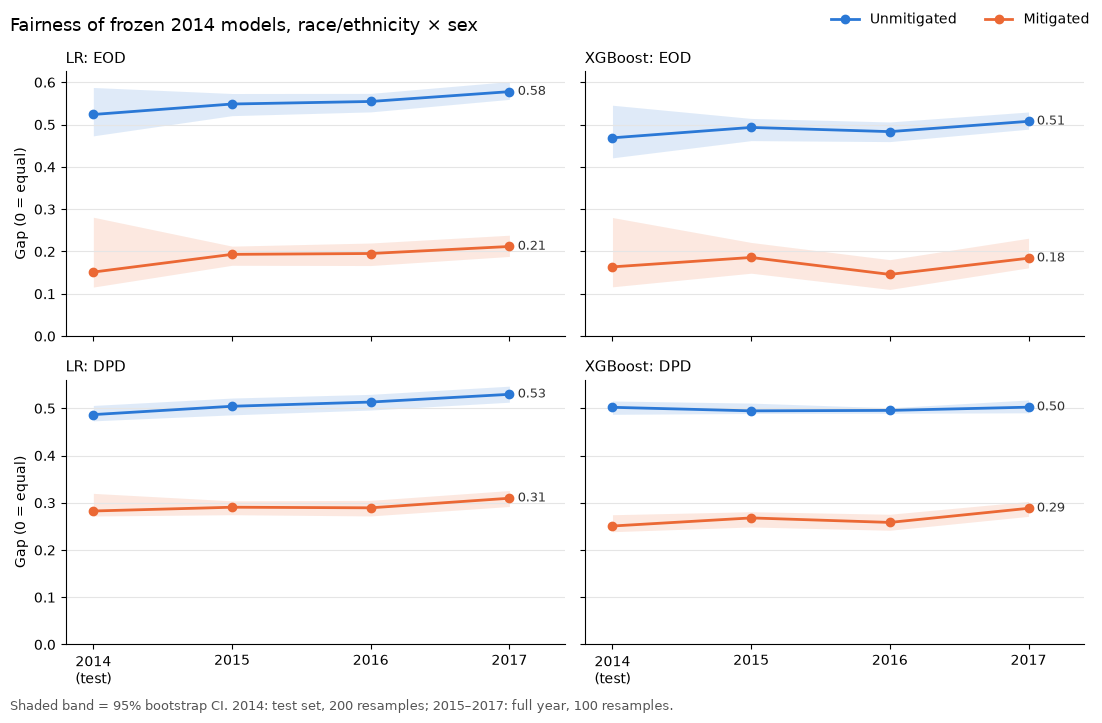

In [12]:
import matplotlib.pyplot as plt

ci = pd.read_csv(CI_PATH)
plot_df = ci[ci["attribute"] == "race_eth_x_sex"]

YEARS = [2014, 2015, 2016, 2017]
COLORS = {False: "#2a78d6", True: "#eb6834"}     # unmitigated = blue, mitigated = orange
LABELS = {False: "Unmitigated", True: "Mitigated"}

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey="row")

for r, metric in enumerate(["EOD", "DPD"]):
    for c, model in enumerate(["LR", "XGBoost"]):
        ax = axes[r, c]
        for mitigated in [False, True]:
            d = plot_df[(plot_df["metric"] == metric)
                        & (plot_df["model"] == model)
                        & (plot_df["mitigated"] == mitigated)].sort_values("year")
            color = COLORS[mitigated]
            ax.fill_between(d["year"], d["ci_low"], d["ci_high"],
                            color=color, alpha=0.15, linewidth=0)
            ax.plot(d["year"], d["value"], color=color, linewidth=2,
                    marker="o", markersize=6, label=LABELS[mitigated])
            last = d.iloc[-1]                     # label only the final value
            ax.annotate(f"{last['value']:.2f}", (last["year"], last["value"]),
                        xytext=(6, 0), textcoords="offset points",
                        va="center", fontsize=9, color="#333333")

        ax.set_title(f"{model}: {metric}", loc="left", fontsize=11)
        ax.set_ylim(bottom=0)
        ax.set_xlim(2013.8, 2017.4)
        ax.set_xticks(YEARS, ["2014\n(test)", "2015", "2016", "2017"])
        ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
        ax.spines[["top", "right"]].set_visible(False)
        if c == 0:
            ax.set_ylabel("Gap (0 = equal)")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, frameon=False)
fig.suptitle("Fairness of frozen 2014 models, race/ethnicity × sex",
             x=0.01, ha="left", fontsize=13)
fig.text(0.01, -0.01,
         "Shaded band = 95% bootstrap CI. 2014: test set, 200 resamples; "
         "2015–2017: full year, 100 resamples.",
         fontsize=9, color="#555555")
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR.parent / "reports" / "fairness_over_time.png",
            dpi=150, bbox_inches="tight")
plt.show()

## Answer to RQ1: does fairness hold over time?

**Mostly yes over three years, but it erodes gradually and unevenly.**

- **No model collapses.** The largest change in any gap from 2014 to 2017 is about +0.05.
- **The benefit of mitigation survives.** In 2017 the mitigated models' EOD (0.21 LR, 0.18 XGBoost) is still far below the unmitigated models' (0.58, 0.51).
- **Unmitigated LR gets steadily worse** on both measures (DPD convincingly, EOD rising every year).
- **Unmitigated XGBoost is flat on DPD,** and its EOD change is within noise.
- **Accuracy falls for every model while AUC stays flat:** the models still rank people well, but their 2014 cutoff no longer fits the 2017 population.

**DPD needs care:** it also moves when the true share of high earners changes between groups (Section 1), so a rising DPD is not automatically a model failure. EOD is the main measure.

**Next, Phase 3 (RQ2): why does fairness change?** Is it inflation or real income growth, a change in who the workers are (feature drift), or a change in how the models use the features (SHAP)?